![Banner](../../../../Images/Banner/05_geostat/05_spatio_temporal_kriging.png)

# Spatio-Temporal Kriging



Ordinary kriging answers a question on a map. At a place you did not sample, it returns the linear unbiased estimate of the measured variable, and the error variance of that estimate, from a single variogram. A monitoring network asks that question with a time attached. A station that was never built. A month that was never reported. The value at that place and that month.

This notebook is the map for the four estimators in this chapter. Space-time ordinary kriging keeps the linear system and gives the covariance a spatial lag and a temporal lag. Convolutional LSTM regression kriging, recurrent graph networks, and graph transformers each fit a spatio-temporal trend and then krige the residual, one month at a time. The notebook writes that shared system, then runs space-time ordinary kriging on twelve stations and one target. The four notebooks that follow keep one family each and carry it through the California PM2.5 network for 2025.

Five notebooks predict a value at a place and a month. The four hands-on notebooks use monthly PM2.5 at the California monitoring network for 2025.

- **Spatio-Temporal Kriging.** This notebook. The shared space-time system, and ordinary kriging on twelve stations and one target.
- **Spatio-Temporal Kriging.** An empirical space-time variogram, a fitted metric model, 25 held-out stations, a one-month forecast, and monthly maps.
- **Convolutional LSTM Regression Kriging.** The same panel as an image sequence, a convolutional-LSTM trend, and residual kriging for each month.
- **Spatio-Temporal GNN Regression Kriging.** A k-nearest-neighbor graph, TGCN and DCRNN cells, and the same hold-out and residual kriging.
- **Spatio-Temporal Graph Transformer Regression Kriging.** Spatial and temporal attention in STTN and GMAN, a sinusoidal encoding of the month, and the same protocol.

Library: `geolattice.geostatistics`




## Table of Contents

- [What this chapter covers](#what-this-chapter-covers)
1. [Notebooks in this chapter](#1-notebooks-in-this-chapter)
2. [How space-time kriging works](#2-how-space-time-kriging-works)
    - 2.1 [The metric model](#the-metric-model)
    - 2.2 [Separable, product-sum, and sum-metric models](#separable-product-sum-and-sum-metric-models)
    - 2.3 [The empirical semivariogram](#the-empirical-semivariogram)
    - 2.4 [A local neighborhood](#a-local-neighborhood)
3. [A neural trend and a kriged residual](#a-neural-trend-and-a-kriged-residual)
    - 3.1 [Convolutional LSTM](#convolutional-lstm)
    - 3.2 [Recurrent graph networks](#recurrent-graph-networks)
    - 3.3 [Graph transformers](#graph-transformers)
4. [Spatio-temporal kriging in GeoLattice](#spatio-temporal-kriging-in-geolattice)
5. [Python setup](#python-setup)
6. [Twelve stations and one target](#twelve-stations-and-one-target)
7. [One target, two questions](#one-target-two-questions)
8. [How to read the estimate](#how-to-read-the-estimate)
9. [Where the next notebooks go](#where-the-next-notebooks-go)
10. [Resources](#resources)
    - 10.1 [The paper or program behind each estimator](#the-paper-or-program-behind-each-estimator)
    - 10.2 [Textbooks that cover the kriging system](#textbooks-that-cover-the-kriging-system)
    - 10.3 [In this library](#in-this-library)


## Overview

Write the ordinary-kriging predictor at an unsampled location $\mathbf{u}_0$ as

$$
\hat Z(\mathbf{u}_0) = \sum_{i=1}^{n} \lambda_i \, Z(\mathbf{u}_i),
$$

with weights from the system in the [kriging introduction](../05_02_kriging/05_02_00_introduction_kriging.ipynb):

$$
\begin{bmatrix}
\mathbf{C} & \mathbf{1} \\
\mathbf{1}^{\top} & 0
\end{bmatrix}
\begin{bmatrix}
\boldsymbol{\lambda} \\
\mu
\end{bmatrix}
=
\begin{bmatrix}
\mathbf{c}_0 \\
1
\end{bmatrix}.
$$

$\mathbf{C}$ holds covariances among the samples, $\mathbf{c}_0$ holds covariances between the samples and the target, and $\mu$ enforces $\sum \lambda_i = 1$ so an unknown constant mean cancels. The kriging variance is $C(0) - \boldsymbol{\lambda}^{\top}\mathbf{c}_0 - \mu$.

A monitoring network reports triples $(\mathbf{u}_i, t_i, Z(\mathbf{u}_i, t_i))$: the same quantity at a set of stations, repeated over time. The predictor keeps the same shape,

$$
\hat Z(\mathbf{u}_0, t_0) = \sum_{i=1}^{N} \lambda_i \, Z(\mathbf{u}_i, t_i),
\qquad
\sum_{i=1}^{N} \lambda_i = 1.
$$

The entries of the matrix become covariances of a joint lag. With spatial lag $h_s = \lVert \mathbf{u}_i - \mathbf{u}_j \rVert$ and temporal lag $h_t = |t_i - t_j|$,

$$
V_{ij} = C(h_s, h_t),
\qquad
v_{0,i} = C\bigl((\mathbf{u}_i, t_i) - (\mathbf{u}_0, t_0)\bigr),
$$

and the kriging variance is unchanged in form, $\sigma^2 = C(0) - \boldsymbol{\lambda}^{\top}\mathbf{v}_0 - \mu$. Covariance and semivariogram are related by $C(h) = C(0) - \gamma(h)$.

### The metric model

The model used in this chapter is the **metric** model (Pebesma, 2012). Space and time are folded into one distance

$$
h_{st} = \sqrt{h_s^2 + (a \, h_t)^2},
$$

and a single variogram $\gamma(h_{st})$ is evaluated at that distance. The anisotropy $a$ (`stAni`) converts a time lag into the units of the map, so the two axes of $h_{st}$ are commensurable. In the worked example below, coordinates are on a unit square and time is a month index, and $a = 0.25$: one month counts as $0.25$ map units inside the square root.

$a$ decides which neighbors win. A large $a$ makes a one-month gap a long distance, so the weights stay with the same month at other stations. A small $a$ makes other months look nearby, so the estimate blends a station's own series. The worked example sets $a$ so that the same month at the nearest station outranks last month at that same station.

`vgm` builds the joint variogram (here a spherical model: a nugget, a partial sill, a range). `vgm_st("metric", joint=..., st_ani=a)` wraps it as the space-time model `STKriging` stores.

### Separable, product-sum, and sum-metric models

`vgm_st` also builds four models in which the spatial range and the temporal range are separate parameters. The [space-time kriging notebook](05_05_01_kriging_st.ipynb) fits the metric model, which is the robust default on a modest panel. The other four are there when that separation is the point of the fit.

| `vgm_st` name | What the covariance does |
|---|---|
| `separable` | A product, $C(h_s, h_t) = C_s(h_s)\, C_t(h_t)$ |
| `productSum` | Spatial variogram, temporal variogram, and their product, with a coefficient $k$ |
| `sumMetric` | A spatial structure, a temporal structure, and a metric joint structure, added |
| `simpleSumMetric` | The same sum, with one shared nugget |
| `metric` | The joint distance $h_{st}$ alone |

### The empirical semivariogram

The empirical semivariogram is the Matheron estimator, binned by spatial lag and temporal lag:

$$
\hat\gamma(h_s, h_t) = \frac{1}{2\,|N(h_s, h_t)|}
\sum_{(i,a),(j,b)\,\in\,N(h_s,h_t)}
\bigl(Z(\mathbf{u}_i, t_a) - Z(\mathbf{u}_j, t_b)\bigr)^2.
$$

`empirical_st_variogram` asks for a complete station $\times$ time matrix: every station observed at every time. `fit_metric_st_variogram` fits the metric model to that cloud. `STKriging.fit` accepts an irregular list of rows, so a station that misses a month can still be a kriging neighbor. The California notebook drops the incomplete stations for the variogram only, and puts them back for the kriging.

### A local neighborhood

Solving the system against every training row scales as $O(N^3)$. `STKriging.predict(..., nmax=k)` builds each prediction from its $k$ nearest neighbors in the scaled coordinates $(x, y, a \cdot t)$, the same local-neighborhood search gstat's `krigeST` uses. Every prediction point is independent, so the local systems are stacked into one batched solve: NumPy on CPU, CuPy on GPU (`use_gpu`). Global kriging (`nmax=np.inf`) keeps the dense path on CPU. The example below uses `nmax=12` and `use_gpu=False`.


---

## A neural trend and a kriged residual

The three notebooks after space-time ordinary kriging keep the kriging system and change the numbers it sees. Each one is regression kriging, the two-step sum from the [regression-kriging introduction](../05_03_regression_kriging/05_03_00_introduction_regression_kriging.ipynb), written at a location $\mathbf{s}$ and a time $t$:

$$
Z(\mathbf{s}, t) = \mu(\mathbf{s}, t) + \varepsilon(\mathbf{s}, t),
\qquad
\hat Z(\mathbf{s}_0, t) = \hat\mu(\mathbf{s}_0, t) + \sum_{i \in \mathcal{O}_t} \lambda_i(t)\, e_i(t).
$$

$\mu$ is a neural trend. The residual $e_i(t) = Z(\mathbf{s}_i, t) - \hat\mu(\mathbf{s}_i, t)$ is ordinary-kriged independently at each time, with a spherical variogram fit to the residuals of that month. Set `krige_residuals=False` and the prediction is the trend alone.

Training follows the masked-reconstruction idea of Wu, Zhuang, Labbé & Sun (2021). Each epoch hides a subset of stations completely, and also hides a random fraction `mask_ratio` of the remaining observed station-months. The network reconstructs the hidden cells from the rest of the panel, so it learns to interpolate. After fitting, out-of-fold reconstructions (each station hidden in turn, then read back) supply the residuals that the variogram sees. At prediction time a new location is attached to the training stations only.

All three classes take the same panel. `coords` has shape `(n_stations, 2)`. `values` has shape `(n_stations, n_times)`, and a NaN is a missing station-month. `predict(coords_pred)` returns an array of shape `(n_pred, n_times)`.

### Convolutional LSTM

`ConvLSTM` paints the stations onto a small image. The training box is padded by 5 percent and split so the longer axis has `grid_size` cells. Each station falls in the nearest pixel; stations that share a pixel are averaged. The input at month $t$ is a two-channel image, masked value and observation mask. A convolutional LSTM (Shi et al., 2015) replaces every gate of an LSTM with a convolution over that image and the previous hidden state, so a pixel's next state is a local function of its neighborhood, shared across the map. The trend at a query coordinate is a bilinear sample of the output image, so the prediction sits at the station's true location.

The raster is the price of that filter. A sparse network is painted onto a coarse grid. The graph models below keep the station coordinates as nodes.

### Recurrent graph networks

`TGCN` and `DCRNN` build a directed $k$-nearest-neighbor graph of the station coordinates. Every node's input at time $t$ is the two-channel vector $[m_{i,t} z_{i,t},\; m_{i,t}]$, with $m_{i,t} \in \{0, 1\}$ the observation mask.

`TGCN` (Zhao et al., 2019) puts a one-hop graph convolution inside a GRU. The convolution is a GraphSAGE mean,

$$
\mathrm{GC}(X) = W_{\mathrm{self}} X + W_{\mathrm{neigh}} D^{-1} A X,
$$

so the hidden state at a month mixes a station's own recent history with the current state of its neighbors.

`DCRNN` (Li, Yu, Shahabi & Liu, 2018) keeps the GRU and replaces each gate with a $K$-hop bidirectional diffusion convolution

$$
H = W_0 X + \sum_{k=1}^{K}\bigl(W_k^{f} P_f^{k} X + W_k^{b} P_b^{k} X\bigr),
$$

where $P_f = D^{-1}A$ and $P_b = D^{-1}A^{\top}$ are the forward and backward random-walk matrices of the same graph. The extra hops, and the two directions, are what `diffusion_k` buys over `TGCN`. The California notebook uses $K = 2$.

### Graph transformers

`STTN` and `GMAN` use the same $k$-nearest-neighbor graph and the same masked input. Attention has no order of its own, so a sinusoidal positional encoding of the month index (Vaswani et al., 2017) is added to every node.

Spatial attention is a graph Transformer layer: scaled dot-product attention, restricted to the incoming edges of each node, softmax-normalized per head. Temporal attention is self-attention across the months of one node.

`STTN` (Xu et al., 2020) runs the spatial block and then the temporal block. `GMAN` (Zheng, Fan, Wang & Qi, 2020) runs them in parallel and mixes them with a learned gate

$$
g = \sigma\bigl(W[h_{\mathrm{spatial}}; h_{\mathrm{temporal}}]\bigr),
\qquad
h = g \odot h_{\mathrm{spatial}} + (1 - g) \odot h_{\mathrm{temporal}}.
$$

That gate is the difference between the two classes. Both are thin aliases of `STGTNRegressionKriging` (`block_type='sttn'` or `'gman'`), just as `TGCN` and `DCRNN` are aliases of `STGNNRegressionKriging` and `ConvLSTM` is an alias of `CNNLSTMRegressionKriging`.


---

## Spatio-temporal kriging in GeoLattice

| Object | Call |
|---|---|
| `vgm` | The joint variogram: `vgm(psill, model, range_, nugget)` |
| `vgm_st` | The space-time model: `vgm_st("metric", joint=..., st_ani=a)`, or `separable`, `productSum`, `sumMetric`, `simpleSumMetric` |
| `empirical_st_variogram` | Matheron cloud on a complete station $\times$ time matrix |
| `fit_metric_st_variogram` | Fit the metric model to that cloud |
| `STKriging` | `STKriging(st_model).fit(coords, times, values)` then `predict(X_pred, T_pred, nmax=)` |
| `ConvLSTM` | `fit(coords, values)` with `values` shaped `(n_stations, n_times)`, then `predict(coords_pred)` |
| `TGCN`, `DCRNN` | The same panel API. `k_neighbors` sets the graph. `diffusion_k` is the DCRNN hop count |
| `STTN`, `GMAN` | The same panel API. `n_heads` is the attention width. The block is sequential (`STTN`) or gated (`GMAN`) |

`use_gpu=False` in the example keeps the kriging arithmetic on NumPy. The four case-study notebooks time the batched neighborhood solve, and the neural training, on CPU and GPU.

`STPoissonKriging` is the estimator for areal counts and rates, where the variance depends on a population. The target in this chapter is a concentration measured at a point.

The calls below run `STKriging` on the twelve-station panel. `ConvLSTM`, `TGCN`, `DCRNN`, `STTN`, and `GMAN` are imported so the names resolve; the California notebooks are where those networks are trained and scored.


---

## Python setup


**Installation.** This notebook needs installation option 4 (core, spatial analysis, spatial statistics and geostatistics): `pip install "geolattice[geostats]"`. See "Installation options" in the GeoLattice README.

In [1]:
%matplotlib inline
import os
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "3")
os.environ.setdefault("TF_ENABLE_ONEDNN_OPTS", "0")

import sys
import warnings

sys.modules.setdefault("tensorflow", None)
warnings.filterwarnings("ignore", category=UserWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import geolattice.geostatistics as gstat
from geolattice.geostatistics import (
    STKriging,
    vgm,
    vgm_st,
    ConvLSTM,
    TGCN,
    DCRNN,
    STTN,
    GMAN,
)

USE_GPU = False  # identical arithmetic on CPU and GPU machines

print(f"geolattice.geostatistics : {gstat.__version__}")
print(
    "trend classes        :",
    ", ".join(cls.__name__ for cls in (ConvLSTM, TGCN, DCRNN, STTN, GMAN)),
)


geolattice.geostatistics : 0.3.44
trend classes        : ConvLSTM, TGCN, DCRNN, STTN, GMAN


---

## Twelve stations and one target

Twelve measurements of a concentration, six months each, and one unsampled target at $(0.50,\ 0.55)$. The samples were built from

$$
\begin{aligned}
w(t) &= \exp\!\left(-\frac{(t - 1)^2}{2 \cdot 1.1^2}\right), \\
h(x, y) &= \exp\!\left(-\frac{(x - 0.38)^2 + (y - 0.48)^2}{2 \cdot 0.08^2}\right), \\
z &= 8 + 6x + 4.5\, w(t) + 5\, h(x, y)\, \bigl(0.4 + 0.6\, w(t)\bigr),
\end{aligned}
$$

and rounded to two decimals. The term in $x$ is a rise toward the east. $w(t)$ is a winter peak centered on month 1, shared by every station. $h(x, y)$ is a short-range hotspot centered on S6, at $(0.38,\ 0.48)$, where month 1 reaches $19.78$.

S11, at $(0.68,\ 0.70)$, is held out of the fit entirely: all six of its months stay out of the training rows, which is the station hold-out the California notebooks use. The target is an unsampled location. On the generating surface it is $16.607$ in month 1 and $11.568$ in month 4. The two samples closest to the target are S6 ($19.78$ in month 1), $0.139$ away, and S7 ($16.15$ in month 1), $0.153$ away. S11 itself sits $0.234$ away, and it is the station left out.

The covariance is set, the same device as the kriging introduction. A spherical joint model, nugget $0.05$, partial sill equal to the variance of the training rows minus that nugget, range $0.70$, and $a = 0.25$. The California notebook estimates this cloud with `empirical_st_variogram` and fits it with `fit_metric_st_variogram`.


In [2]:
stations = pd.DataFrame({
    "station": [f"S{i}" for i in range(1, 13)],
    "x": [0.12, 0.28, 0.48, 0.70,
          0.18, 0.38, 0.58, 0.82,
          0.22, 0.45, 0.68, 0.85],
    "y": [0.18, 0.22, 0.15, 0.20,
          0.45, 0.48, 0.42, 0.50,
          0.72, 0.78, 0.70, 0.82],
})

def field(x, y, t):
    winter = np.exp(-0.5 * ((t - 1.0) / 1.1) ** 2)
    hotspot = np.exp(-((x - 0.38) ** 2 + (y - 0.48) ** 2) / (2 * 0.08 ** 2))
    return 8.0 + 6.0 * x + 4.5 * winter + 5.0 * hotspot * (0.4 + 0.6 * winter)

months = np.arange(6, dtype=float)
xy = stations[["x", "y"]].to_numpy(float)
Z = np.round([[field(x, y, t) for t in months] for x, y in xy], 2)
for t, col in enumerate(months.astype(int)):
    stations[f"m{col}"] = Z[:, t]

hold_name = "S11"
hold = int(stations.index[stations["station"] == hold_name][0])
train_idx = [i for i in range(len(stations)) if i != hold]

coords, times, values = [], [], []
for i in train_idx:
    for t in months:
        coords.append(xy[i])
        times.append(float(t))
        values.append(Z[i, int(t)])
coords = np.asarray(coords, float)
times = np.asarray(times, float)
values = np.asarray(values, float)

target = np.array([0.50, 0.55])
print(f"training rows : {len(values)}  ({len(train_idx)} stations x {len(months)} months)")
print(f"held out      : {hold_name} at ({xy[hold, 0]:.2f}, {xy[hold, 1]:.2f})")
print(f"target        : ({target[0]:.2f}, {target[1]:.2f})")
stations.round(2)


training rows : 66  (11 stations x 6 months)
held out      : S11 at (0.68, 0.70)
target        : (0.50, 0.55)


,station,x,y,m0,m1,m2,m3,m4,m5
0,S1,0.12,0.18,11.70,13.22,11.70,9.58,8.83,8.73
1,S2,0.28,0.22,12.67,14.19,12.67,10.55,9.79,9.69
2,S3,0.48,0.15,13.86,15.38,13.86,11.74,10.99,10.89
3,S4,0.70,0.20,15.18,16.70,15.18,13.06,12.31,12.21
4,S5,0.18,0.45,12.22,13.78,12.22,10.05,9.27,9.17
5,S6,0.38,0.48,17.24,19.78,17.24,13.72,12.46,12.29
6,S7,0.58,0.42,14.59,16.15,14.59,12.43,11.66,11.55
7,S8,0.82,0.50,15.90,17.42,15.90,13.78,13.03,12.93
8,S9,0.22,0.72,12.30,13.83,12.30,10.19,9.43,9.33
9,S10,0.45,0.78,13.68,15.20,13.68,11.56,10.81,10.71


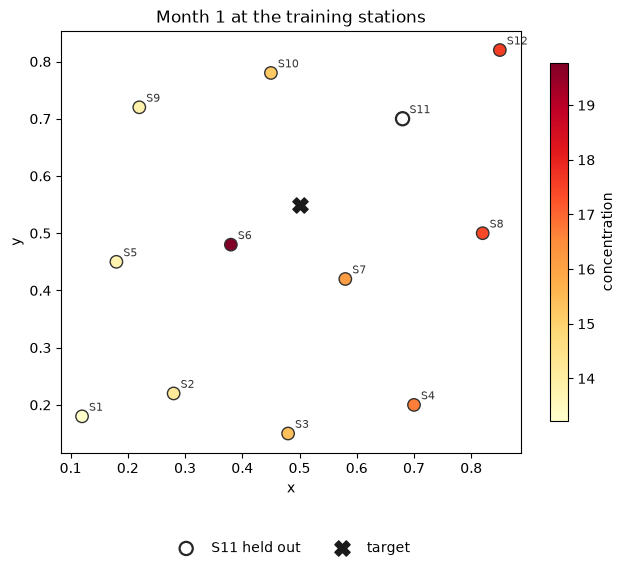

In [3]:
month1 = Z[:, 1]
fig, ax = plt.subplots(figsize=(6.6, 5.6))
sc = ax.scatter(
    xy[train_idx, 0], xy[train_idx, 1],
    c=month1[train_idx], s=80, cmap="YlOrRd",
    edgecolor="0.2", zorder=3, vmin=month1.min(), vmax=month1.max(),
)
ax.scatter(
    xy[hold, 0], xy[hold, 1],
    s=90, facecolor="none", edgecolor="0.15", linewidth=1.6,
    zorder=4, label=f"{hold_name} held out",
)
ax.scatter(
    target[0], target[1],
    marker="X", s=120, c="0.1", zorder=5, label="target",
)
for i, name in enumerate(stations["station"]):
    ax.annotate(
        name, (xy[i, 0], xy[i, 1]),
        textcoords="offset points", xytext=(5, 4), fontsize=8, color="0.2",
    )
ax.set_aspect("equal")
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_title("Month 1 at the training stations")
ax.legend(
    frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.18), ncol=2,
)
fig.colorbar(sc, ax=ax, label="concentration", shrink=0.85)
fig.tight_layout()
fig.subplots_adjust(bottom=0.22)


---

## One target, two questions

The metric model is the spherical joint variogram described above. `STKriging` stores the 66 training rows (eleven stations, six months) and predicts with the twelve nearest neighbors in $(x, y, 0.25 \cdot t)$.

Two predictions are the chapter in miniature. The target is an unsampled location. S11 is a station whose whole series was withheld. S6 in month 1 is a training row, and the same call reproduces it.


In [4]:
train_var = float(np.var(values))
nugget, range_, st_ani = 0.05, 0.70, 0.25
partial_sill = train_var - nugget
joint = vgm(psill=partial_sill, model="spherical", range_=range_, nugget=nugget)
st_model = vgm_st("metric", joint=joint, st_ani=st_ani)

stk = STKriging(st_model, use_gpu=USE_GPU).fit(coords, times, values)

def predict_series(pt):
    zhat, sig = stk.predict(
        np.repeat(np.atleast_2d(pt), len(months), axis=0),
        months,
        nmax=12,
    )
    return zhat, sig

z_target, se_target = predict_series(target)
z_hold, se_hold = predict_series(xy[hold])
z_s6, se_s6 = stk.predict(xy[[5]], np.array([1.0]), nmax=12)

rows = []
for t in months.astype(int):
    rows.append({
        "where": "target",
        "month": t,
        "observed": np.nan,
        "surface": field(target[0], target[1], t),
        "estimate": z_target[t],
        "se": se_target[t],
    })
for t in months.astype(int):
    rows.append({
        "where": hold_name,
        "month": t,
        "observed": Z[hold, t],
        "surface": field(xy[hold, 0], xy[hold, 1], t),
        "estimate": z_hold[t],
        "se": se_hold[t],
    })
report = pd.DataFrame(rows)
rmse_hold = float(np.sqrt(np.mean((Z[hold] - z_hold) ** 2)))

print(
    f"metric model : spherical, nugget {nugget:.2f}, "
    f"partial sill {partial_sill:.3f}, range {range_:.2f}, stAni {st_ani:.2f}"
)
print(f"S6 month 1  : observed {Z[5, 1]:.2f}, estimate {float(z_s6[0]):.3f}, se {float(se_s6[0]):.3f}")
print(f"S11 RMSE    : {rmse_hold:.3f}")
report.round(3)


metric model : spherical, nugget 0.05, partial sill 5.926, range 0.70, stAni 0.25
S6 month 1  : observed 19.78, estimate 19.780, se 0.000
S11 RMSE    : 0.183


,where,month,observed,surface,estimate,se
0,target,0,NaN,14.859,15.904,1.388
1,target,1,NaN,16.607,17.548,1.400
2,target,2,NaN,14.859,15.762,1.400
3,target,3,NaN,12.432,13.163,1.400
4,target,4,NaN,11.568,12.119,1.400
5,target,5,NaN,11.450,11.900,1.388
6,S11,0,15.06,15.057,15.357,1.605
7,S11,1,16.58,16.580,16.343,1.629
8,S11,2,15.06,15.057,14.997,1.629
9,S11,3,12.94,12.942,13.051,1.629


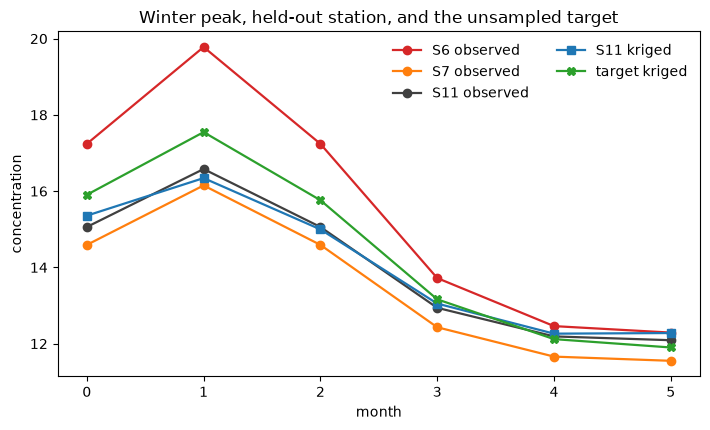

In [5]:
fig, ax = plt.subplots(figsize=(7.2, 4.4))
series = {
    "S6 observed": Z[5],
    "S7 observed": Z[6],
    "S11 observed": Z[hold],
    "S11 kriged": z_hold,
    "target kriged": z_target,
}
styles = {
    "S6 observed": ("o", "C3"),
    "S7 observed": ("o", "C1"),
    "S11 observed": ("o", "0.25"),
    "S11 kriged": ("s", "C0"),
    "target kriged": ("X", "C2"),
}
for name, y in series.items():
    marker, color = styles[name]
    ax.plot(months, y, marker=marker, color=color, label=name, linewidth=1.6)
ax.set_xticks(months)
ax.set_xlabel("month")
ax.set_ylabel("concentration")
ax.set_title("Winter peak, held-out station, and the unsampled target")
ax.legend(frameon=False, ncol=2)
fig.tight_layout()


---

## How to read the estimate

The training variance is $5.976$. The spherical model therefore has nugget $0.05$, partial sill $5.926$, range $0.70$, and $a = 0.25$. A same-month neighbor at map distance $0.14$ has joint distance $0.14$. The same station one month away has joint distance $\sqrt{0.14^2 + 0.25^2} = 0.29$. With `nmax=12`, the nearest rows to the target in month 1 are S6 at month 1 ($h_{st} = 0.139$, value $19.78$), S7 at month 1 ($0.153$, $16.15$), and S10 at month 1 ($0.235$, $15.20$). S6 at month 0 and at month 2 come next, both at $0.286$. The same month at a nearby station outranks an adjacent month at the nearest station, which is what $a = 0.25$ was set to do.

**At a training row the interpolator reproduces the sample.** S6 in month 1 is one of the 66 rows passed to `fit`. The estimate is $19.780$ and the standard error is $0$. $\gamma(0) = 0$, so the colocated observation takes weight 1. The nugget is the jump as you step away from that row. On the row itself the value is known.

**The target in month 1 is $17.548$, with standard error $1.400$.** The generating surface there is $16.607$. S6 sits on the hotspot and the target sits on its shoulder, $0.139$ away, so the linear weights are pulled toward $19.78$. S7 at $16.15$ pulls the other way. $17.548$ lands between those two neighbors, above the surface. A spherical model of range $0.70$ averages the samples the neighborhood contains, and the Gaussian bump that generated the hotspot is only $0.08$ wide, so the spike reaches the target as the pull from S6.

**Month 4 at the same coordinates is $12.119$, with the same standard error $1.400$.** The surface there is $11.568$. The winter term $w(t)$ has decayed, and the neighbors' month-4 values sit near $12$: S6 is $12.46$, S7 is $11.66$. The weights follow those rows because a four-month gap is a long joint distance ($a \cdot 4 = 1.0$, past the range $0.70$), and the covariance with month 1 is zero. The standard error matches month 1 because it is a function of that covariance geometry. At month 0 and month 5 the time window is one-sided, and the standard error is $1.388$.

**S11, withheld entirely, tracks the winter peak.** Its month-1 estimate is $16.343$ against the observation $16.58$, and its month-4 estimate is $12.262$ against $12.19$. The root-mean-square error over the six months is $0.183$. The standard error is $1.629$ in the interior months, larger than the $1.400$ at the target: the target sits between S6 and S7, and S11 is a station that was removed, so its neighborhood is thinner. The curve still rises in month 1 and falls after month 2, which is the space-time covariance doing the work a single-month ordinary kriging would do one map at a time, here from one fit.


---

## Where the next notebooks go

The call above is space-time ordinary kriging with a covariance that was set on twelve stations. What it leaves out is a real network, a fitted variogram, a held-out score, and the three trend models that krige a residual.

| Next notebook | What it adds to the call you just ran |
|---|---|
| [Spatio-temporal kriging](05_05_01_kriging_st.ipynb) | 163 California stations, daily PM2.5 aggregated to 12 months, `empirical_st_variogram` and `fit_metric_st_variogram`, 25 stations held out, a forecast at month index 12, and a 5 km map of the kriging standard error |
| [ConvLSTM regression kriging](05_05_02_kriging_cnn_lstm.ipynb) | The same panel painted onto a 32-cell image, a two-layer `ConvLSTM`, residual ordinary kriging per month, and a grid comparison with the `STKriging` surface |
| [Spatio-temporal GNN regression kriging](05_05_03_kriging_stgnn.ipynb) | A $k$-nearest-neighbor graph (`k_neighbors=8`), `TGCN` and `DCRNN` trained with masked reconstruction, and the same hold-out against the classical surface |
| [Graph-transformer regression kriging](05_05_04_kriging_stgtn.ipynb) | `STTN` and `GMAN` on that graph, sinusoidal month encodings, and the same score and the same maps |

Open the notebook whose question matches the table at the top. Each one assumes the ordinary-kriging system from the classic-kriging chapter, the trend-plus-residual sum from the regression-kriging chapter, and the one-section version of its own estimator written here.


---

## Resources

### The paper or program behind each estimator

| Reference | Estimator |
|---|---|
| Pebesma, E. (2012). spacetime: Spatio-Temporal Data in R. *Journal of Statistical Software* 51(7). | `krigeST` and the metric, separable, product-sum, and sum-metric models. `STKriging` is a Python port |
| Cressie, N. & Wikle, C.K. (2011). *Statistics for Spatio-Temporal Data*. Wiley. | Space-time random fields |
| Shi, X., Chen, Z., Wang, H., Yeung, D.-Y., Wong, W.-K. & Woo, W.-C. (2015). Convolutional LSTM network: a machine learning approach for precipitation nowcasting. *NeurIPS*. | `ConvLSTM` |
| Zhao, L., Song, Y., Zhang, C., Liu, Y., Wang, P., Lin, T., Deng, M. & Li, H. (2020). T-GCN: a temporal graph convolutional network for traffic prediction. *IEEE Transactions on Intelligent Transportation Systems* 21(9). | `TGCN` |
| Li, Y., Yu, R., Shahabi, C. & Liu, Y. (2018). Diffusion convolutional recurrent neural network: data-driven traffic forecasting. *ICLR*. | `DCRNN` |
| Xu, M., Dai, W., Liu, C., Gao, X., Lin, W., Qi, G.-J. & Xiong, H. (2020). Spatial-temporal transformer networks for traffic flow forecasting. arXiv:2001.02908. | `STTN` |
| Zheng, C., Fan, X., Wang, C. & Qi, J. (2020). GMAN: a graph multi-attention network for traffic prediction. *AAAI*. | `GMAN` |
| Wu, Y., Zhuang, D., Labbé, A. & Sun, L. (2021). Inductive graph neural networks for spatiotemporal kriging. *AAAI*. | The masked reconstruction used to train the three trend classes |
| Vaswani, A. et al. (2017). Attention is all you need. *NeurIPS*. | The sinusoidal month encoding in `STTN` and `GMAN` |

### Textbooks that cover the kriging system

| Reference | What to read it for |
|---|---|
| Chilès, J.-P. & Delfiner, P. (2012). *Geostatistics: Modeling Spatial Uncertainty* (2nd ed.). Wiley. | The kriging system and the kriging variance |
| Goovaerts, P. (1997). *Geostatistics for Natural Resources Evaluation*. Oxford. | Ordinary kriging in practice, and the regression-kriging sum |

### In this library

| Object | Role |
|---|---|
| `STKriging` | Space-time ordinary kriging. `fit` stores the rows; `predict` returns the estimate and the standard error |
| `vgm`, `vgm_st` | A joint variogram, and one of `metric`, `separable`, `productSum`, `sumMetric`, `simpleSumMetric` |
| `empirical_st_variogram`, `fit_metric_st_variogram` | The Matheron cloud on a complete panel, and the metric fit used in the California notebook |
| `ConvLSTM` | Convolutional-LSTM trend, bilinear readout, residual kriging per month |
| `TGCN`, `DCRNN` | Recurrent graph trend on a $k$-nearest-neighbor graph, plus the same residual kriging |
| `STTN`, `GMAN` | Graph-transformer trend, sequential or gated, plus the same residual kriging |
| `STPoissonKriging` | Space-time kriging for areal rates |
| `OrdinaryKriging`, `RegressionKriging` | The linear reference, and the trend-plus-residual sum, from the earlier chapters |
